# Assignment 1 — South German Credit
Data Science for Business · 2026–2027

Student 1: Athulya Mohandas Menon - r1070436  
Student 2: name and r-number

Complete this notebook in Python. Keep your code and relevant outputs here; write the report in `A1_Template.docx`. The full instructions are in `A1_Assignment.pdf`.

In Colab: upload this `.ipynb` to Drive, open it with **Google Colaboratory**, then click **Connect**. Upload `South_German_Credit.csv` through **Files**. Locally, keep the CSV in the working folder or update `DATA_PATH`.

## 0. Load the dataset
Run the two cells below, then start Question 1.


In [69]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# other imports needed for analysis
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, roc_auc_score

In [70]:
DATA_PATH = Path("South_German_Credit.csv")
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        "Upload South_German_Credit.csv to the Colab Files panel, "
        "or set DATA_PATH to the CSV location on your computer."
    )

credit = pd.read_csv(DATA_PATH)
display(credit.head())

,status,duration,credit_history,purpose,amount,savings,employment_duration,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,number_credits,job,people_liable,telephone,foreign_worker,credit_risk
0,1,18,4,2,1049,1,2,4,2,1,...,2,21,3,1,1,3,2,1,2,1
1,1,9,4,0,2799,1,3,2,3,1,...,1,36,3,1,2,3,1,1,2,1
2,2,12,2,9,841,2,4,2,2,1,...,1,23,3,1,1,2,2,1,2,1
3,1,12,4,0,2122,1,3,3,3,1,...,1,39,3,1,2,2,1,1,1,1
4,1,12,4,0,2171,1,3,4,3,1,...,2,38,1,2,2,2,2,1,1,1


## 1. Explore the data
Follow Question 1 on page 3: check the data, create the target (1 = bad, 0 = good) and make the required stratified 70/30 split before exploring relationships.

Choose two variables and compare their joint groups in one figure. Put your choices, figure and interpretation in report Part 1. Keep checks and supporting calculations here.


In [71]:
print("Dimensions:", credit.shape)
print("Variable types:", credit.dtypes.astype(str).value_counts().to_dict(), "-> all numeric")
print("Missing values:", credit.isna().sum().sum())
print("Duplicate rows:", credit.duplicated().sum())
print("credit_risk counts (0 = bad, 1 = good):", credit["credit_risk"].value_counts().sort_index().to_dict())

# Modelling target: 1 = bad, 0 = good 
credit["bad"] = 1 - credit["credit_risk"]
print("bad counts (1 = bad, 0 = good):", credit["bad"].value_counts().sort_index().to_dict())
# no missing values and no duplicates so nothing is removed or imputed.

# reproducible stratified 70/30 split 
# training data is used for exploration and model building; test data for the final evaluation.
SEED = 2026
train, test = train_test_split(credit, test_size=0.30, random_state=SEED, stratify=credit["bad"])
print(f"\nRandom seed {SEED}: train = {len(train)} rows ({train['bad'].sum()} bad, {train['bad'].mean():.0%}), "
      f"test = {len(test)} rows ({test['bad'].sum()} bad, {test['bad'].mean():.0%})")


Dimensions: (1000, 21)
Variable types: {'int64': 21} -> all numeric
Missing values: 0
Duplicate rows: 0
credit_risk counts (0 = bad, 1 = good): {0: 300, 1: 700}
bad counts (1 = bad, 0 = good): {0: 700, 1: 300}

Random seed 2026: train = 700 rows (210 bad, 30%), test = 300 rows (90 bad, 30%)


In [72]:
status_codebook = {1: "no checking account", 2: "balance < 0 DM", 3: "0–200 DM", 4: "≥ 200 DM / salary"}

check = train.groupby("status")["bad"].agg(n="size", bad_rate="mean")
check["share of applicants"] = check["n"] / len(train)
check.insert(0, "label in the code book", check.index.map(status_codebook))
display(check.round(2))

,label in the code book,n,bad_rate,share of applicants
status,,,,
1,no checking account,186,0.48,0.27
2,balance < 0 DM,188,0.39,0.27
3,0–200 DM,50,0.22,0.07
4,≥ 200 DM / salary,276,0.13,0.39


With the code-book labels, applicants with no checking account (code 1) would be the **riskiest** group (48% bad credits, 27% of applicants), while applicants with *≥ 200 DM or a salary account* (code 4) would be the **largest** group (39% of applicants) with only about 13% bad credits. This is weird: having no checking account should not be the worst sign, and it is unlikely that 4 in 10 applicants held ≥ 200 DM.

Online discourse also mentioned that there was a mislabelling in this dataset so we chose instead to use the corrected labels where
 order **1 = balance < 0 DM, 2 = 0–200 DM, 3 = ≥ 200 DM / salary, 4 = no checking account** wherein the bad rate falls as the balance rises (48% → 39% → 22%) and the large group without a checking account is the safest (13%)

**Action:** we use these corrected labels for `status` in the rest of the notebook (labels only; data unchanged).

In [73]:
labels = {
 "status": {1: "balance < 0 DM", 2: "0–200 DM", 3: "≥ 200 DM / salary", 4: "no checking account"},
 "credit_history": {0: "past payment delays", 1: "critical / credits elsewhere", 2: "no credits / all repaid", 3: "existing credits paid duly", 4: "all credits here repaid"},
 "purpose": {0: "other", 1: "new car", 2: "used car", 3: "furniture/equipment", 4: "radio/TV", 5: "domestic appliances", 6: "repairs", 7: "education", 8: "vacation", 9: "retraining", 10: "business"},
 "savings": {1: "unknown / none", 2: "< 100 DM", 3: "100–500 DM", 4: "500–1,000 DM", 5: "≥ 1,000 DM"},
 "employment_duration": {1: "unemployed", 2: "< 1 year", 3: "1–4 years", 4: "4–7 years", 5: "≥ 7 years"},
 "installment_rate": {1: "≥ 35% of income", 2: "25–35%", 3: "20–25%", 4: "< 20%"},
 "personal_status_sex": {1: "male, divorced/separated", 2: "female non-single / male single", 3: "male, married/widowed", 4: "female, single"},
 "other_debtors": {1: "none", 2: "co-applicant", 3: "guarantor"},
 "present_residence": {1: "< 1 year", 2: "1–4 years", 3: "4–7 years", 4: "≥ 7 years"},
 "property": {1: "unknown / none", 2: "car or other", 3: "savings agr. / life insurance", 4: "real estate"},
 "other_installment_plans": {1: "bank", 2: "stores", 3: "none"},
 "housing": {1: "free", 2: "rent", 3: "own"},
 "number_credits": {1: "1", 2: "2–3", 3: "4–5", 4: "≥ 6"},
 "job": {1: "unemployed / unskilled non-res.", 2: "unskilled resident", 3: "skilled employee", 4: "manager / self-employed"},
 "people_liable": {1: "3 or more", 2: "0 to 2"},
 "telephone": {1: "no", 2: "yes"},
 "foreign_worker": {1: "yes", 2: "no"},
}

In [74]:
status_group = {1: "balance < 0 DM", 2: "balance < 200 DM", 3: "≥ 200 DM / salary or no checking account", 4: "≥ 200 DM / salary or no checking account"}
status_order = ["balance < 0 DM", "balance < 200 DM", "≥ 200 DM / salary or no checking account"]
dur_order = ["≤ 12 months", "13–24 months", "> 24 months"]

def joint_groups(df, cuts=(0, 12, 24, 100), names=dur_order):
    s = df["status"].map(status_group).rename("checking account")
    d = pd.cut(df["duration"], list(cuts), labels=names).rename("credit duration")
    g = df.groupby([s, d], observed=True)["bad"].agg(n="size", bad="sum")
    g["bad_rate"] = g["bad"] / g["n"]
    return g

print("Bad rate by checking account:", train.groupby(train["status"].map(status_group))["bad"].mean().round(2).to_dict())
print("Bad rate by duration        :", train.groupby(pd.cut(train["duration"], [0, 12, 24, 100], labels=dur_order), observed=True)["bad"].mean().round(2).to_dict())

g = joint_groups(train)
display(g.round(2))
display(g["bad_rate"].unstack().round(2))

B = train["bad"].sum()
top_rate, top_bad = g["bad_rate"].idxmax(), g["bad"].idxmax()
print(f"\nHighest bad-credit rate : {top_rate} -> {g.loc[top_rate, 'bad_rate']:.0%} (n = {g.loc[top_rate, 'n']})")
print(f"Most bad credits        : {top_bad} -> {g.loc[top_bad, 'bad']} of {B} bad credits ({g.loc[top_bad, 'bad'] / B:.0%}), rate {g.loc[top_bad, 'bad_rate']:.0%}, n = {g.loc[top_bad, 'n']}")
print(f"Group sizes             : smallest n = {g['n'].min()}, largest n = {g['n'].max()}")

# Reliability: do the conclusions change with other durations
# Can see that it is mostly stable and keeping the cuts as done earlier might be better for interpretation as the fine cutting of the duration under 2 years does not add moe 
g_alt = joint_groups(train, cuts=(0, 12, 18, 24,100), names=["≤ 12 months", "12–18 months","18–24 months", "> 24 months"])
print(f"Other cut points        : highest rate {g_alt['bad_rate'].idxmax()} ({g_alt['bad_rate'].max():.0%}); most bad credits {g_alt['bad'].idxmax()} ({g_alt['bad'].max()})")

Bad rate by checking account: {'balance < 0 DM': 0.48, 'balance < 200 DM': 0.39, '≥ 200 DM / salary or no checking account': 0.14}
Bad rate by duration        : {'≤ 12 months': 0.19, '13–24 months': 0.3, '> 24 months': 0.47}


n  bad  bad_rate
checking account                         credit duration                    
balance < 0 DM                           ≤ 12 months       64   21      0.33
                                         13–24 months      77   38      0.49
                                         > 24 months       45   30      0.67
balance < 200 DM                         ≤ 12 months       64   16      0.25
                                         13–24 months      63   24      0.38
                                         > 24 months       61   34      0.56
≥ 200 DM / salary or no checking account ≤ 12 months      134   14      0.10
                                         13–24 months     134   20      0.15
                                         > 24 months       58   13      0.22

credit duration,≤ 12 months,13–24 months,> 24 months
checking account,,,
balance < 0 DM,0.33,0.49,0.67
balance < 200 DM,0.25,0.38,0.56
≥ 200 DM / salary or no checking account,0.10,0.15,0.22



Highest bad-credit rate : ('balance < 0 DM', '> 24 months') -> 67% (n = 45)
Most bad credits        : ('balance < 0 DM', '13–24 months') -> 38 of 210 bad credits (18%), rate 49%, n = 77
Group sizes             : smallest n = 45, largest n = 134
Other cut points        : highest rate ('balance < 0 DM', '> 24 months') (67%); most bad credits ('balance < 200 DM', '> 24 months') (34)


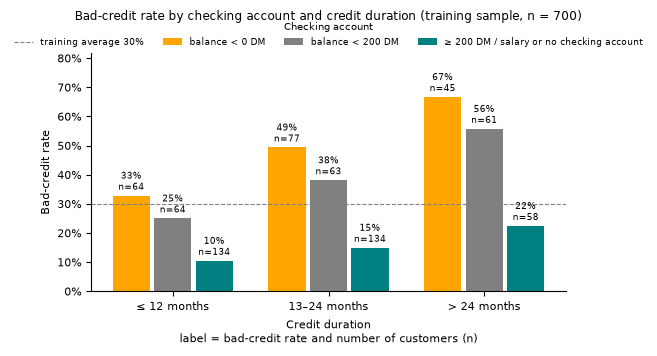

In [75]:
colours = [ORANGE, GREY, TEAL]
fig, ax = plt.subplots(figsize=(6.4, 3.6))
w = 0.8 / len(status_order)
for i, s in enumerate(status_order):
    for j, d in enumerate(dur_order):
        r = g.loc[(s, d)]
        x = j + (i - 1) * w
        ax.bar(x, r["bad_rate"], w * 0.9, color=colours[i], label=s if j == 0 else None)
        ax.text(x, r["bad_rate"] + 0.01, f"{r['bad_rate']:.0%}\nn={int(r['n'])}", ha="center", va="bottom", fontsize=6.5)
avg = train["bad"].mean()
ax.axhline(avg, ls="--", lw=0.8, color=GREY, label=f"training average {avg:.0%}")
ax.set_xticks(range(len(dur_order))); ax.set_xticklabels(dur_order)
ax.set_ylim(0, g["bad_rate"].max() + 0.15)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Credit duration\nlabel = bad-credit rate and number of customers (n)")
ax.set_ylabel("Bad-credit rate")
ax.set_title(f"Bad-credit rate by checking account and credit duration (training sample, n = {len(train)})", fontsize=8.5, pad=24)
ax.legend(title="Checking account", ncol=4, fontsize=6.8, title_fontsize=7, frameon=False, loc="lower center", bbox_to_anchor=(0.5, 0.99))
fig.tight_layout();
plt.show()

## 2. Build and evaluate the model
Follow Question 2 on page 4. Select predictors, including at least one quantitative variable, define their levels and apply WOE. Fit logistic regression using only those WOE predictors; calculate IV and compare training/test ROC curves and AUC.

Justify choices and interpret results in report Part 2. Keep calculations, WOE tables and model coefficients here.


### 2.1 Predictors, levels and WOE

[credit_history] Binned ['all credits here repaid', 'existing credits paid duly'] --> 'Risk Tier 1 (Low Risk)'
[purpose] Binned ['new car', 'furniture/equipment', 'vacation'] --> 'Risk Tier 1 (Low Risk)'
[purpose] Binned ['used car', 'repairs', 'other'] --> 'Risk Tier 2 (Medium Risk)'
[purpose] Binned ['retraining', 'domestic appliances'] --> 'Risk Tier 3 (Medium Risk)'
[purpose] Binned ['radio/TV', 'business'] --> 'Risk Tier 4 (High Risk)'
[employment_duration] Binned ['≥ 7 years', '4–7 years'] --> 'Risk Tier 1 (Low Risk)'


,IV
status,0.539
savings,0.300
duration,0.242
purpose,0.227
credit_history,0.200
amount,0.125
age,0.102
property,0.101
employment_duration,0.093
housing,0.072


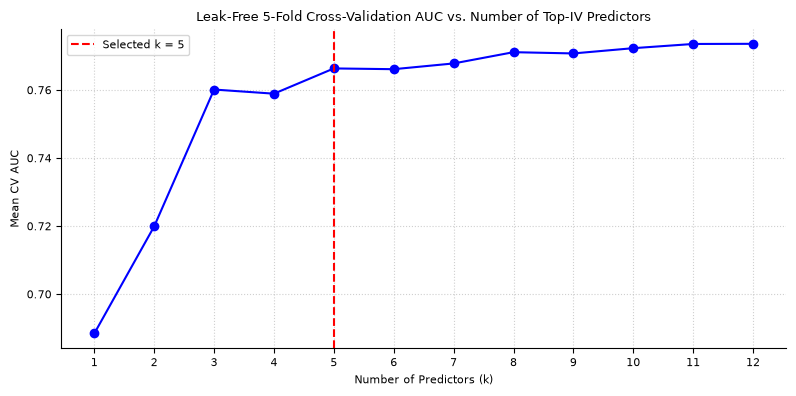


Selected predictors: ['status', 'savings', 'duration', 'purpose', 'credit_history']


In [105]:
status_group = {  1: "balance < 0 DM",   2: "balance < 200 DM",  3: "≥ 200 DM / salary or no checking account",   4: "≥ 200 DM / salary or no checking account"}

dur_cuts = [0, 12, 24, 100]
dur_order = ["≤ 12 months", "13–24 months", "> 24 months"]

cuts = {"duration": dur_cuts}
for v in ["amount", "age"]:
    cuts[v] = sorted(set(int(round(q)) for q in train[v].quantile([0.25, 0.5, 0.75])))
unit = {"duration": "", "amount": " DM", "age": " years"}

def cut_labels(v):
    c, u = cuts[v], unit[v]
    if v == "duration":
        return dur_order
    return [f"≤ {c[0]}{u}"] + [f"{a + 1}–{b}{u}" for a, b in zip(c[:-1], c[1:])] + [f"> {c[-1]}{u}"]

def create_risk_bins(df, y_col, max_bins=4):
    level_map = {}
    merges_summary = {}
    
    categorical_vars = [col for col in labels.keys() if col != "status"]
    
    for v in categorical_vars:
        if v == "savings":
            level_map[v] = {cat: labels[v].get(cat, cat) for cat in labels[v]}
            merges_summary[v] = {}
            continue
            
        cat_bad_rates = df.groupby(v)[y_col].mean().sort_values()
        
        n_cats = len(cat_bad_rates)
        n_bins = min(max_bins, n_cats) 
        groups = np.array_split(cat_bad_rates.index, n_bins)
        
        mapping = {}
        inv_map = {}
        for i, group_cats in enumerate(groups):
            tier_name = f"Risk Tier {i+1} (Low Risk)" if i == 0 else (f"Risk Tier {i+1} (High Risk)" if i == n_bins - 1 else f"Risk Tier {i+1} (Medium Risk)")
            for cat in group_cats:
                orig_name = labels[v].get(cat, cat)
                mapping[cat] = tier_name
                inv_map.setdefault(tier_name, []).append(orig_name)
                
        level_map[v] = mapping
        merges_summary[v] = {tier: origs for tier, origs in inv_map.items() if len(origs) > 1}
        
    return level_map, merges_summary

level_name, merged_report = create_risk_bins(train, "bad", max_bins=4)

for var, merges in merged_report.items():
    if merges:
        for target, originals in merges.items():
            print(f"[{var}] Binned {originals} --> '{target}'")

def levels(df, v):
    if v == "status": return df["status"].map(status_group)
    if v == "duration": return pd.cut(df["duration"], dur_cuts, labels=dur_order)
    if v in cuts:  return pd.cut(df[v], [-np.inf] + cuts[v] + [np.inf], labels=cut_labels(v))
    return df[v].map(level_name[v])

def woe_table(level, y):
    counts = pd.crosstab(level, y).reindex(columns=[0, 1], fill_value=0)
    good, bad = counts[0] + 0.5, counts[1] + 0.5
    t = pd.DataFrame({"n": counts.sum(axis=1), "bad_rate": counts[1] / counts.sum(axis=1)})
    t["woe"] = np.log((good / good.sum()) / (bad / bad.sum()))
    t["iv"] = (good / good.sum() - bad / bad.sum()) * t["woe"]          
    return t

exclude = ["personal_status_sex", "foreign_worker"]  # Ethical/legal exclusions
predictors = [c for c in credit.columns if c not in ["credit_risk", "bad"] + exclude]

global_iv = pd.Series({v: woe_table(levels(train, v), train["bad"])["iv"].sum() for v in predictors}).sort_values(ascending=False)
display(global_iv.round(3).to_frame("IV"))

y_train = train["bad"]
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_results = {}

max_k = min(12, len(global_iv))
for k in range(1, max_k + 1):
    top_k_vars = list(global_iv.index[:k])
    aucs = []
    
    for train_idx, val_idx in kf.split(train):
        tr_fold = train.iloc[train_idx].copy()
        val_fold = train.iloc[val_idx].copy()
        
        fold_level_name, _ = create_risk_bins(tr_fold, "bad", max_bins=4)
        
        def fold_levels(df_in, v):
            if v == "status": return df_in["status"].map(status_group)
            if v == "duration": return pd.cut(df_in["duration"], dur_cuts, labels=dur_order)
            if v in cuts:  return pd.cut(df_in[v], [-np.inf] + cuts[v] + [np.inf], labels=cut_labels(v))
            return df_in[v].map(fold_level_name[v])
            
        fold_tables = {v: woe_table(fold_levels(tr_fold, v), tr_fold["bad"]) for v in global_iv.index}
        fold_woe_map = {v: dict(zip(t.index.astype(str), t["woe"])) for v, t in fold_tables.items()}
        
        def transform_fold(df_in):
            res = pd.DataFrame()
            for v in global_iv.index:
                res[v] = fold_levels(df_in, v).astype(str).map(fold_woe_map[v])
            return res
        
        X_tr_fold = transform_fold(tr_fold)[top_k_vars].fillna(0)
        X_val_fold = transform_fold(val_fold)[top_k_vars].fillna(0)
        
        model_cv = LogisticRegression(solver="lbfgs", random_state=42)
        model_cv.fit(X_tr_fold, tr_fold["bad"])
        
        preds = model_cv.predict_proba(X_val_fold)[:, 1]
        aucs.append(roc_auc_score(val_fold["bad"], preds))
    
    cv_results[k] = np.mean(aucs)

cv_df = pd.Series(cv_results).to_frame("Mean_CV_AUC")

plt.figure(figsize=(8, 4))
plt.plot(list(cv_results.keys()), list(cv_results.values()), marker='o', linestyle='-', color='b')
plt.axvline(x=5, color='r', linestyle='--', label='Selected k = 5')
plt.title("Leak-Free 5-Fold Cross-Validation AUC vs. Number of Top-IV Predictors")
plt.xlabel("Number of Predictors (k)")
plt.ylabel("Mean CV AUC")
plt.xticks(range(1, max_k + 1))
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

k_selected = 5
final_vars = list(global_iv.index[:k_selected])
if not any(v in cuts for v in final_vars):
    best_cut_var = [v for v in global_iv.index if v in cuts][0]
    final_vars[-1] = best_cut_var

print("\nSelected predictors:", final_vars)

tables = {v: woe_table(levels(train, v), train["bad"]) for v in final_vars}
woe_map = {v: dict(zip(t.index.astype(str), t["woe"])) for v, t in tables.items()}

In [106]:
def to_woe(df):
    return pd.DataFrame({v: levels(df, v).astype(str).map(woe_map[v]) for v in final_vars})

X_train, X_test = to_woe(train), to_woe(test)

model = LogisticRegression(C=np.inf, max_iter=1000).fit(X_train, train["bad"])         
coef = pd.Series(model.coef_[0], index=final_vars)

print("\nCoefficients:")
print(coef.round(3).to_string())
print("Intercept:", round(model.intercept_[0], 3))
# coefficients are negative: the model predicts P(bad), and a higher WOE (= ln good/bad) means a safer level


top = iv_final.idxmax()
print(f"\nHighest training IV: {top} (IV = {iv_final[top]:.3f}). Its levels, from safest to riskiest:")
display(tables[top].sort_values("woe", ascending=False).round(3))


Coefficients:
status           -0.756
savings          -0.947
duration         -1.005
purpose          -0.819
credit_history   -0.846
Intercept: -0.837

Highest training IV: status (IV = 0.539). Its levels, from safest to riskiest:


,n,bad_rate,woe,iv
status,,,,
≥ 200 DM / salary or no checking account,326,0.144,0.929,0.320
balance < 200 DM,188,0.394,-0.413,0.049
balance < 0 DM,186,0.478,-0.758,0.170


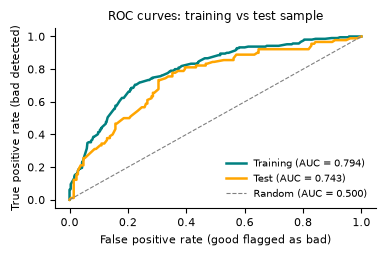

AUC training 0.794 | AUC test 0.743 | gap (training - test) = +0.052
Riskiest 30% of the test applicants: 51% bad credits; the other 70%: 21%


In [107]:
p_train, p_test = model.predict_proba(X_train)[:, 1], model.predict_proba(X_test)[:, 1]
auc_train, auc_test = roc_auc_score(train["bad"], p_train), roc_auc_score(test["bad"], p_test)

fig, ax = plt.subplots(figsize=(3.9, 2.6))
for y, p, name, colour in [(train["bad"], p_train, "Training", TEAL), (test["bad"], p_test, "Test", ORANGE)]:
    fpr, tpr, _ = roc_curve(y, p)
    ax.plot(fpr, tpr, color=colour, lw=1.8, label=f"{name} (AUC = {roc_auc_score(y, p):.3f})")
ax.plot([0, 1], [0, 1], "--", color=GREY, lw=0.8, label="Random (AUC = 0.500)")
ax.set_xlabel("False positive rate (good flagged as bad)"); ax.set_ylabel("True positive rate (bad detected)")
ax.set_title("ROC curves: training vs test sample", fontsize=8.5); ax.legend(loc="lower right", frameon=False, fontsize=7)
fig.tight_layout(); fig.savefig("fig2_roc.png", dpi=300, bbox_inches="tight"); plt.show()

print(f"AUC training {auc_train:.3f} | AUC test {auc_test:.3f} | gap (training - test) = {auc_train - auc_test:+.3f}")

risky = p_test >= np.quantile(p_test, 0.70)
print(f"Riskiest 30% of the test applicants: {test['bad'][risky].mean():.0%} bad credits; the other 70%: {test['bad'][~risky].mean():.0%}")

## 3. Construct the scorecard
Follow Question 3 on page 5. Use 600 points at good:bad odds of 50:1 and 20 points to double those odds. Verify the scorecard against model probabilities on all test rows and check its scale.

Put the full scorecard and test-score boxplots in report Part 3, highlighting the two cases requested. Keep derivations and checks here.


### 3.1 How the points are derived
Score = Offset + Factor × ln(odds good:bad), with Factor = 20 / ln 2 (20 points double the odds) and Offset = 600 − Factor × ln 50 (600 points = odds 50:1).
The model gives ln(odds bad) = b0 + Σ bⱼ·WOEⱼ, so ln(odds good) = −b0 − Σ bⱼ·WOEⱼ. Every level therefore gets
**points = −Factor × bⱼ × WOE + (Offset − Factor × b0) / m**, where m is the number of predictors (offset and intercept are shared equally). A customer's score is the sum of the points of his or her levels.

In [110]:
factor = 20 / np.log(2)                         
offset = 600 - factor * np.log(50)              
m = len(final_vars)
base = (offset - factor * model.intercept_[0]) / m           
print(f"Factor = {factor:.3f}, Offset = {offset:.3f}, base points per predictor = {base:.2f}")

rows = [{"predictor": v, "level": level, "points_exact": -factor * coef[v] * woe + base}
        for v in final_vars for level, woe in woe_map[v].items()]
scorecard = pd.DataFrame(rows)
scorecard["points"] = scorecard["points_exact"].round().astype(int)           
display(scorecard.assign(predictor=scorecard["predictor"].str.replace("_", " "))[["predictor", "level", "points"]])

def total_points(df, column):
    lookup = {(r.predictor, r.level): getattr(r, column) for r in scorecard.itertuples()}
    return sum(levels(df, v).astype(str).map(lambda lvl: lookup[(v, lvl)]) for v in final_vars)

score_exact, score_card = total_points(test, "points_exact"), total_points(test, "points")
p = pd.Series(p_test, index=test.index)
score_model = offset + factor * np.log((1 - p) / p)                     
print(f"Rounded points vs model score  : max |difference| = {(score_card - score_model).abs().max():.1f} points, mean = {(score_card - score_model).abs().mean():.2f}")

for odds in [50, 100, 200]:
    print(f"odds {odds}:1 -> {offset + factor * np.log(odds):.0f} points")
slope, icpt = np.polyfit(score_card, np.log((1 - p) / p), 1)             
print(f"On the test applicants: odds at 600 points = {np.exp(icpt + slope * 600):.1f}:1, points that double the odds = {np.log(2) / slope:.1f}")
print(f"Mean score of good credits {score_card[test['bad'] == 0].mean():.0f} vs bad credits {score_card[test['bad'] == 1].mean():.0f} (higher = lower risk)")

Factor = 28.854, Offset = 487.123, base points per predictor = 102.26


,predictor,level,points
0,status,balance < 0 DM,86
1,status,balance < 200 DM,93
2,status,≥ 200 DM / salary or no checking account,123
3,savings,100–500 DM,125
4,savings,"500–1,000 DM",140
5,savings,< 100 DM,100
6,savings,unknown / none,93
7,savings,"≥ 1,000 DM",127
8,duration,≤ 12 months,119
9,duration,13–24 months,102


Rounded points vs model score  : max |difference| = 1.4 points, mean = 0.39
odds 50:1 -> 600 points
odds 100:1 -> 620 points
odds 200:1 -> 640 points
On the test applicants: odds at 600 points = 50.0:1, points that double the odds = 20.1
Mean score of good credits 526 vs bad credits 498 (higher = lower risk)


Highest-scoring bad credit : row 949, 601 points (model P(bad) = 2%)
Lowest-scoring good credit : row 594, 430 points (model P(bad) = 88%)


,status,savings,duration,purpose,credit_history,credit_risk
949,4,5,12,3,4,0
594,1,1,30,2,0,1


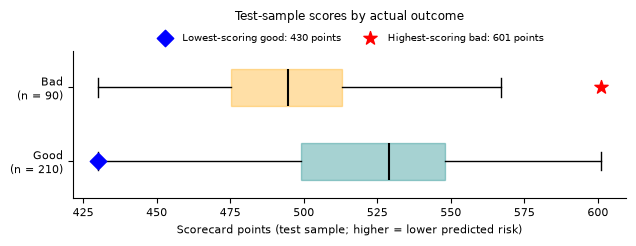

In [111]:
good_scores, bad_scores = score_card[test["bad"] == 0], score_card[test["bad"] == 1]
bad_hi, good_lo = bad_scores.idxmax(), good_scores.idxmin()                 # highest-scoring bad, lowest-scoring good
print(f"Highest-scoring bad credit : row {bad_hi}, {score_card[bad_hi]} points (model P(bad) = {p[bad_hi]:.0%})")
print(f"Lowest-scoring good credit : row {good_lo}, {score_card[good_lo]} points (model P(bad) = {p[good_lo]:.0%})")
display(credit.loc[[bad_hi, good_lo], final_vars + ["credit_risk"]])

fig, ax = plt.subplots(figsize=(6.4, 2.5))
try:
    bp = ax.boxplot([good_scores, bad_scores], orientation="horizontal", widths=0.5, patch_artist=True, showfliers=False)
except TypeError:
    bp = ax.boxplot([good_scores, bad_scores], vert=False, widths=0.5, patch_artist=True, showfliers=False)

for box, colour in zip(bp["boxes"], [TEAL, ORANGE]): 
    box.set(facecolor=colour, alpha=0.35, edgecolor=colour)
for med in bp["medians"]: 
    med.set(color="black", lw=1.5)

ax.scatter(score_card[good_lo], 1, s=70, marker="D", color="blue", zorder=5, label=f"Lowest-scoring good: {score_card[good_lo]} points")
ax.scatter(score_card[bad_hi], 2, s=100, marker="*", color="red", zorder=5, label=f"Highest-scoring bad: {score_card[bad_hi]} points")

ax.set_yticks([1, 2])
ax.set_yticklabels([f"Good\n(n = {len(good_scores)})", f"Bad\n(n = {len(bad_scores)})"])
ax.set_xlabel("Scorecard points (test sample; higher = lower predicted risk)")
ax.set_title("Test-sample scores by actual outcome", fontsize=8.5, pad=22)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 0.99), ncol=2, frameon=False, fontsize=7)
fig.tight_layout()
plt.show()